# **Customer Segmentation 🛒🛍️ — Part 1: Data Cleaning**

# **Introduction**

**Customer Segmentation** is the process of dividing a company's customers into groups based on shared characteristics like demographics, behaviors, or needs. This allows businesses to tailor marketing messages, sales strategies, and products to be more relevant and effective for each specific group, ultimately leading to increased customer loyalty and conversions.

In this project, we will segment customers based on their purchasing behavior using unsupervised learning.

**Project roadmap:** This notebook is the first of four in the customer segmentation project:

1. **Data cleaning** (this notebook)
2. **EDA and simple RFM analysis**
3. **Product categorization** (~20 categories and ~40 subcategories)
4. **Customer clustering**

The cleaned dataset produced here (`data/cleaned_data.csv`) is the input for the following notebooks, which will be added to this repository progressively.

**Data:** In this project we use the **Online Retail Dataset** available at [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail).

**Acknowledgements:**
Thanks for the assistance received by using the *UCI Machine Learning Repository*.
Dua, D. and Graff, C. (2019). [UCI Machine Learning Repository](http://archive.ics.uci.edu/ml). Irvine, CA: University of California, School of Information and Computer Science.

**Relevant paper:**
[1] D. Chen. "Online Retail," UCI Machine Learning Repository, 2015. [Online]. Available at: https://doi.org/10.24432/C5BW33.

**Features:**
- **InvoiceNo:** A 6-digit integral number uniquely assigned to each transaction. If this code starts with letter 'c', it indicates a cancellation.
- **StockCode:** A 5-digit integral number uniquely assigned to each distinct product.
- **Description:** Product name.
- **Quantity:** The quantities of each product (item) per transaction.
- **InvoiceDate:** The day and time when each transaction was generated.
- **UnitPrice:** Product price per unit.
- **CustomerID:** A 5-digit integral number uniquely assigned to each customer.
- **Country:** The name of the country where each customer resides.

**Dataset notes (not in the official UCI documentation):**

- Product descriptions are written in uppercase. Several records that are *not* physical products (`Discount`, `Manual`, `Bank Charges`, `Next Day Carriage`, `CRUK Commission`, `High Resolution Image`) are written in mixed case, so lowercase letters are a useful hint to detect them. Other non-product records, such as `POSTAGE`, are uppercase, but their `StockCode` does not follow the product pattern (digits, optionally followed by a letter).
- This is only a heuristic: a few real products also contain lowercase characters (units like `500g` or `45x45cm`, or typos like `TRADITIONAl`). For this reason, the candidates are reviewed manually in section 3.5.1, and `Description` is not lowercased before that step (see 3.3).

## **1. Import Libraries**

In [1]:
# Libraries for downloading and extracting data
import urllib.request
import ssl
import certifi
import zipfile
import os
import tempfile

# Libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 1000)
pd.set_option('display.max_colwidth', None)


# Record package versions to make the analysis environment easier to reproduce.

package_dict = {}

from platform import python_version
package_dict['python'] = python_version()

from matplotlib import __version__ as mptl_version
package_dict['matplotlib'] = mptl_version

for package in [pd, np, sns]:
    if hasattr(package, '__version__'):
        package_dict[package.__name__] = package.__version__
    else:
        package_dict[package.__name__] = 'Version not available'

print("Package's version:")
for k in sorted(package_dict):
    print(f'  - {k:<14} {package_dict[k]}')

Package's version:
  - matplotlib     3.11.2
  - numpy          2.5.3
  - pandas         3.0.6
  - python         3.14.3
  - seaborn        0.13.2


## **2. Load Data**

In [2]:
# Configuration: source URL, local paths, and identifier data types.
url = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
extract_folder = 'data'
csv_file = 'raw_data.csv'
csv_path = os.path.join(extract_folder, csv_file)
dict_types = {
    'InvoiceNo'  : 'str',
    'StockCode'  : 'str',
    'Description': 'str',
    'CustomerID' : 'str',
    'Country'    : 'str'
}

# Reuse the local CSV when available; otherwise download and convert the source file
if os.path.isfile(csv_path):
    print(f'csv file found at "{csv_path}". Loading from disk ... ', end='')
    df_raw = pd.read_csv(csv_path, parse_dates=['InvoiceDate'], dtype=dict_types)
    print('Ready.')
else:
    print('csv file not found.\n  - Downloading from UCI ... ', end='')

    # Create destination folder if it does not exist
    os.makedirs(extract_folder, exist_ok=True)

    # SSL context with up-to-date certificates
    ssl_context = ssl.create_default_context(cafile=certifi.where())

    # Use a temporary directory
    with tempfile.TemporaryDirectory() as tmp_dir:
        zip_file = os.path.join(tmp_dir, 'online_retail.zip')

        # Download
        with urllib.request.urlopen(url, context=ssl_context) as response:
            with open(zip_file, 'wb') as out_file:
                out_file.write(response.read())
        print('Download complete.')

        # Extract into the temporary directory
        with zipfile.ZipFile(zip_file, 'r') as zip_ref:
            zip_ref.extractall(tmp_dir)

        # Find the extracted Excel file (ignoring the .zip)
        excel_file = [
            f for f in os.listdir(tmp_dir)
            if f.lower().endswith(('.xlsx', '.xls'))
        ][0]
        excel_path = os.path.join(tmp_dir, excel_file)

        # Read Excel
        print(f'  - Reading "{excel_file}" ... ', end='')
        df_raw = pd.read_excel(excel_path, dtype=dict_types)

        # Save as CSV in the final folder
        df_raw.to_csv(csv_path, index=False)
        print(f'Converted to csv and saved at "{csv_path}".')

    # When leaving the `with` block, the temporary directory (with the .zip
    # and the .xlsx) is automatically deleted.

features = df_raw.columns.to_list()

# Inspect the dataset's dimensions, columns, sample rows, and inferred data types.
print(f'\nData dimension: {df_raw.shape}\n')
print(f'Features: {features}\n')
print("Data Overview:\n")
display(df_raw.head())
print("Data types:\n")
df_raw.info()

csv file not found.
  - Downloading from UCI ... Download complete.
  - Reading "Online Retail.xlsx" ... Converted to csv and saved at "data\raw_data.csv".

Data dimension: (541909, 8)

Features: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Overview:



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


Data types:

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  str           
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(5)
memory usage: 61.5 MB


## **3. Clean Data**

Each step below detects one type of problem, decides whether to fix or remove it, and prints how many rows were affected.

### **3.1 Duplicate Rows**

In [3]:
# Count exact duplicate rows; keep all copies until their meaning is understood.
print(f'Exact duplicate rows: {df_raw.duplicated().sum()}\n')

duplicated_rows = df_raw.duplicated(keep=False)

print("Duplicates Overview:\n")
df_raw[duplicated_rows].sort_values(by=features).sort_values(['InvoiceNo', 'Description']).head(10)

Exact duplicate rows: 5268

Duplicates Overview:



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
611,536412,22900,SET 2 TEA TOWELS I LOVE LONDON,2,2010-12-01 11:49:00,2.95,17920,United Kingdom
617,536412,22900,SET 2 TEA TOWELS I LOVE LONDON,2,2010-12-01 11:49:00,2.95,17920,United Kingdom


In [4]:
# Select a specific invoice containing seemingly duplicated rows to inspect it in detail.
# This allows to demonstrate that these duplicates represent genuine physical transactions 
# rather than system registration errors.
invoiceNo = '536409'

print(f"Records for Invoice number {invoiceNo}:\n")
df_raw[df_raw.InvoiceNo==invoiceNo].sort_values('Description').head(10)

Records for Invoice number 536409:



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
483,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,3,2010-12-01 11:45:00,6.35,17908,United Kingdom
498,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,1,2010-12-01 11:45:00,6.35,17908,United Kingdom
525,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,2,2010-12-01 11:45:00,6.35,17908,United Kingdom
516,536409,22075,6 RIBBONS ELEGANT CHRISTMAS,1,2010-12-01 11:45:00,1.65,17908,United Kingdom
520,536409,22074,6 RIBBONS SHIMMERING PINKS,1,2010-12-01 11:45:00,1.65,17908,United Kingdom
518,536409,21326,AGED GLASS SILVER T-LIGHT HOLDER,12,2010-12-01 11:45:00,0.65,17908,United Kingdom
531,536409,22153,ANGEL DECORATION STARS ON DRESS,6,2010-12-01 11:45:00,0.42,17908,United Kingdom
491,536409,85116,BLACK CANDELABRA T-LIGHT HOLDER,1,2010-12-01 11:45:00,2.10,17908,United Kingdom


As we can observe, there are rows that appear to be duplicates. However, a detailed inspection reveals that these are actually different products registered within the very same minute under the same invoice. So we conclude that duplicated rows do not mean an erroneous recording of transactions, and they are kept.

### **3.2 Missing Values Overview**

In [5]:
def check_missings(df):
    """Report the total number of missing values and list affected columns."""
    total_missings = df.isna().sum().sum()
    print(f'Number of missing values: {total_missings}')
    if total_missings > 0:
        for col in df.columns:
            if df[col].isna().sum() > 0:
                print(f'  - {col:<11}:{df[col].isna().sum():>7}')

check_missings(df_raw)

Number of missing values: 136534
  - Description:   1454
  - CustomerID : 135080


### **3.3 Text Normalization**

`InvoiceNo`, `StockCode` and `Country` are lowercased and stripped of extra spaces so that identical values are written identically.

`Description` is **not** normalized yet: its letter case is a hint to detect non-product records (see the dataset notes in the introduction), so it is lowercased in section 3.5.1, right after that inspection.

In [6]:
# Keep the raw DataFrame unchanged and apply cleaning steps to a separate copy
df_clean = df_raw.copy()


def clean_text_series(s):
    """
    Clean a pandas Series of strings:
      - lower case
      - collapse multiple spaces
      - remove leading/trailing spaces
    """
    return (
        s
        .str.lower()                            # lowercase
        .str.replace(r'\s+', ' ', regex=True)   # collapse multiple spaces
        .str.strip()                            # remove leading/trailing spaces
    )


cols_to_clean = ['InvoiceNo', 'StockCode', 'Country']

df_clean[cols_to_clean] = df_clean[cols_to_clean].apply(clean_text_series, axis=0)

### **3.4 Missing CustomerID: Impute or Drop?**

Customer segmentation needs to know *who* bought each item, so rows without `CustomerID` are only useful if the customer can be recovered.

An invoice belongs to a single customer. Therefore, a missing `CustomerID` can be recovered only if another line of the **same invoice** (same `Country` and `InvoiceNo`) has the customer filled in. The next cell counts how many invoices with a missing customer can be recovered this way.

In [7]:
inv_key = ['Country', 'InvoiceNo']

# Identify invoices with and without CustomerID, using country + invoice as the invoice key
known = df_clean.loc[df_clean['CustomerID'].notna(), inv_key + ['CustomerID']].drop_duplicates()
missing = df_clean.loc[df_clean['CustomerID'].isna(), inv_key].drop_duplicates()

# Sanity check: every known invoice belongs to a single customer
assert not known.duplicated(inv_key).any()

n_recoverable = len(missing.merge(known, on=inv_key, how='inner'))

print(f'Invoices with a known customer:   {len(known):>6}')
print(f'Invoices with a missing customer: {len(missing):>6}')
print(f'  - recoverable from other lines: {n_recoverable:>6}')
print(f'  - not recoverable:              {len(missing) - n_recoverable:>6}')

Invoices with a known customer:    22190
Invoices with a missing customer:   3710
  - recoverable from other lines:      0
  - not recoverable:                3710


None of the invoices with a missing customer can be recovered, so imputation is not possible and those rows are removed. The cell below still contains the imputation step, which is skipped when there is nothing to recover.

In [8]:
# Fill CustomerID only when another line from the same invoice provides it
# If no invoice can be matched, this recovery step is skipped
if n_recoverable > 0:
    df_clean = df_clean.merge(known.rename(columns={'CustomerID': 'CustomerID_known'}), on=inv_key, how='left')
    df_clean['CustomerID'] = df_clean['CustomerID'].fillna(df_clean['CustomerID_known'])
    df_clean = df_clean.drop(columns='CustomerID_known')

# Remove the remaining rows without customer
num_rows_before = df_clean.shape[0]
print(f'Number of rows before removing missing CustomerID values: {num_rows_before}')

mask_missing_customer = df_clean['CustomerID'].isna()
row_value = df_clean['UnitPrice'] * df_clean['Quantity']
share_rows = mask_missing_customer.mean()
share_value = row_value[mask_missing_customer].sum() / row_value.sum()

df_clean = df_clean[~mask_missing_customer].reset_index(drop=True)

num_rows_after = df_clean.shape[0]
print(f'Number of rows after  removing missing CustomerID values: {num_rows_after}')

if num_rows_before != num_rows_after:
    print(f'Number of rows removed: {num_rows_before - num_rows_after} '
          f'({share_rows:.1%} of rows, {share_value:.1%} of net sales value)')
else:
    print('No rows were removed')

Number of rows before removing missing CustomerID values: 541909
Number of rows after  removing missing CustomerID values: 406829
Number of rows removed: 135080 (24.9% of rows, 14.9% of net sales value)


**Note on Data Loss:** Although removing these rows results in a significant reduction of the dataset (approximately 24.9% of total rows and 14.9% of net sales value), this step is strictly necessary. For subsequent stages—such as **RFM Analysis** and **Customer Clustering**—we rely entirely on tracking individual purchasing behaviors over time. Anonymous transactions cannot be aggregated at a customer level, making them unusable for customer segmentation.

In [9]:
# Check final missings
check_missings(df_clean)

Number of missing values: 0


### **3.5 Product Codes and Descriptions**

#### **3.5.1 Removing Non-Product Lines (postage, fees, discounts)**

There are 3 types of "StockCode" compositions:
1. Sequence of digits
2. Sequence of digits ending in a letter
3. One or more letters followed or not by one or more digits

In the third case there is a high probability that the codes are related to financial or logistic terms that are not relevant in this analysis.

In [10]:
mask_letter_codes = df_clean['StockCode'].str.contains(r'^[a-z]', regex=True)

codes_with_letter = df_clean.loc[mask_letter_codes, 'StockCode'].unique()

print(f'Unique StockCodes starting with a letter: {len(codes_with_letter)}\n')
if len(codes_with_letter) > 0:
    print(f'StockCodes starting with a letter:\n{codes_with_letter.tolist()}')

Unique StockCodes starting with a letter: 8

StockCodes starting with a letter:
['post', 'd', 'c2', 'm', 'bank charges', 'pads', 'dot', 'cruk']


Almost all product descriptions are written in uppercase. When a description has lowercase letters it is likely to be related to financial or logistic terms, although a few real products also contain lowercase characters (units, typos). Let's list the candidates and review them manually.

In [11]:
mask_lowers = df_clean['Description'].str.contains(r'[a-z]', regex=True)

descriptions_with_lower = df_clean.loc[mask_lowers, 'Description'].unique()

print(f'Unique descriptions containing lowercase letters: {len(descriptions_with_lower)}\n')
if len(descriptions_with_lower) > 0:
    print(f'Descriptions containing lowercase letters:\n{descriptions_with_lower.tolist()}')

Unique descriptions containing lowercase letters: 23

Descriptions containing lowercase letters:
['Discount', 'BAG 500g SWIRLY MARBLES', 'POLYESTER FILLER PAD 45x45cm', 'POLYESTER FILLER PAD 45x30cm', 'POLYESTER FILLER PAD 40x40cm', 'FRENCH BLUE METAL DOOR SIGN No', 'Manual', 'BAG 250g SWIRLY MARBLES', 'BAG 125g SWIRLY MARBLES', '3 TRADITIONAl BISCUIT CUTTERS  SET', 'Bank Charges', 'NUMBER TILE COTTAGE GARDEN No', 'FOLK ART GREETING CARD,pack/12', 'ESSENTIAL BALM 3.5g TIN IN ENVELOPE', 'POLYESTER FILLER PAD 65CMx65CM', 'NUMBER TILE VINTAGE FONT No ', 'POLYESTER FILLER PAD 30CMx30CM', 'POLYESTER FILLER PAD 60x40cm', 'FLOWERS HANDBAG blue and orange', 'Next Day Carriage', 'THE KING GIFT BAG 25x24x12cm', 'CRUK Commission', 'High Resolution Image']


In [12]:
# Candidate descriptions were reviewed manually in the preceding inspection cells.
non_product_descriptions = ['discount', 'manual', 'bank charges', 'next day carriage',
                            'cruk commission', 'high resolution image']

# Descriptions are normalized only now, after the case-based inspection
df_clean['Description'] = clean_text_series(df_clean['Description'])


def non_product_mask(df):
    """Boolean mask of lines whose code or description does not belong to a product."""
    return df['StockCode'].isin(codes_with_letter) | df['Description'].isin(non_product_descriptions)


print('Combinations of "StockCode" and "Description" that are apparently not valid products:\n')
df_non_product = df_clean.loc[non_product_mask(df_clean), ['StockCode', 'Description']].drop_duplicates()
df_non_product

Combinations of "StockCode" and "Description" that are apparently not valid products:



,StockCode,Description
45,post,postage
141,d,discount
1422,c2,carriage
1698,m,manual
3219,bank charges,bank charges
110121,pads,pads to match all cushions
146426,23444,next day carriage
230911,dot,dotcom postage
230912,cruk,cruk commission
302189,23702,high resolution image


In [13]:
print('Analyze whether or not to delete rows with description "high resolution image":\n')
df_clean[df_clean['Description'] == 'high resolution image']

Analyze whether or not to delete rows with description "high resolution image":



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
302189,571739,23702,high resolution image,1,2011-10-19 10:33:00,3.0,12500,germany
346829,575910,23702,high resolution image,2,2011-11-11 16:05:00,1.5,14836,united kingdom
355513,576659,23702,high resolution image,1,2011-11-16 11:09:00,21.0,15373,united kingdom


There are just 3 records with varying unit prices, so it's better to delete them.

In [14]:
print('Analyze whether or not to delete rows with description "pads to match all cushions":\n')
df_clean[df_clean['Description'] == 'pads to match all cushions']

Analyze whether or not to delete rows with description "pads to match all cushions":



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
110121,550193,pads,pads to match all cushions,1,2011-04-15 09:27:00,0.001,13952,united kingdom
199246,561226,pads,pads to match all cushions,1,2011-07-26 10:13:00,0.001,15618,united kingdom
262429,568158,pads,pads to match all cushions,1,2011-09-25 12:22:00,0.000,16133,united kingdom
263645,568200,pads,pads to match all cushions,1,2011-09-25 14:58:00,0.001,16198,united kingdom


There are just four records with prices that are symbolic, so it's better to delete them.

In [15]:
# Remove lines identified as non-products and report the impact on row count.
num_rows_before = df_clean.shape[0]
print(f'Rows before removing non-product lines: {num_rows_before}')

mask_non_product = non_product_mask(df_clean)

if mask_non_product.sum() > 0:
    print(f'Non-product lines identified: {mask_non_product.sum()}')
    df_clean = df_clean[~mask_non_product].reset_index(drop=True)
    num_rows_after = df_clean.shape[0]
    print(f'Rows after removing non-product lines: {num_rows_after}')
    print(f'Non-product rows removed: {num_rows_before - num_rows_after}')
else:
    print('No rows were removed')

Rows before removing non-product lines: 406829
Non-product lines identified: 2003
Rows after removing non-product lines: 404826
Non-product rows removed: 2003


#### **3.5.2 One Description per StockCode**

In [16]:
def print_number_unique_codes_descriptions(df):
    """Print the number of unique stock codes and unique descriptions (products)."""
    number_unique_codes = df['StockCode'].nunique()
    print(f'Number of unique codes: {number_unique_codes}')
    number_unique_products = df['Description'].nunique()
    print(f'Number of unique products: {number_unique_products}')

print_number_unique_codes_descriptions(df_clean)

Number of unique codes: 3674
Number of unique products: 3867


In [17]:
# Check whether each original StockCode maps to a single product description.
df_code_unique_descriptions = df_clean.groupby('StockCode')['Description'].agg(
    Nunique_Descriptions='nunique',
    Descriptions='unique',
    Last_Description='last'# get last description
)

mask_more_than_1_description = df_code_unique_descriptions['Nunique_Descriptions'] > 1

has_conflicts = mask_more_than_1_description.any()
print(f"Is there just one unique description per product code? {'No' if has_conflicts else 'Yes'}")
if has_conflicts:
    df_more_than_1_description = df_code_unique_descriptions[mask_more_than_1_description]
    print(f'Number of Stock Codes with more than one description: {df_more_than_1_description.shape[0]}')
    print("\nConflicting stock codes and their unique descriptions (top 5):\n")
    display(df_more_than_1_description.sort_values('Nunique_Descriptions', ascending=False).head())

    # Replace Description with more than one value withLast_Description
    mask_codes = df_clean['StockCode'].isin(df_more_than_1_description.index)
    df_clean.loc[mask_codes, 'Description'] = df_clean.loc[mask_codes, 'StockCode'].map(
        df_more_than_1_description['Last_Description'])

    print(f'{mask_codes.sum()} rows were fixed')

# Check again number of unique codes and descriptions
print_number_unique_codes_descriptions(df_clean)

Is there just one unique description per product code? No
Number of Stock Codes with more than one description: 205

Conflicting stock codes and their unique descriptions (top 5):



,Nunique_Descriptions,Descriptions,Last_Description
StockCode,,,
23236,4,"[doiley storage tin, doiley biscuit tin, storage tin vintage doily, storage tin vintage doiley]",storage tin vintage doily
23196,4,"[retro leaves magnetic notepad, reto leaves magnetic shopping list, leaves magnetic shopping list, vintage leaf magnetic notepad]",vintage leaf magnetic notepad
22776,3,"[sweetheart cakestand 3 tier, cakestand, 3 tier, loveheart, sweetheart 3 tier cake stand]",sweetheart 3 tier cake stand
22937,3,"[baking mould chocolate cupcakes, baking mould chocolate cup cakes, baking mould cupcake chocolate]",baking mould chocolate cupcakes
17107d,3,"[flower fairy,5 summer b'draw liners, flower fairy 5 drawer liners, flower fairy 5 summer draw liners]",flower fairy 5 drawer liners


37621 rows were fixed
Number of unique codes: 3674
Number of unique products: 3645


#### **3.5.3 One ProductCode per Description**

The opposite case: the same description appears under different stock codes.

In [18]:
def get_mode_code(codes):
    """Most frequent code. Ties are broken by choosing the smallest code, so the result is deterministic."""
    counts = codes.value_counts()
    return min(counts[counts == counts.max()].index)


# Find descriptions associated with multiple codes and choose a representative code.
df_description_unique_codes = df_clean.groupby('Description')['StockCode'].agg(
    Nunique_Codes='nunique',
    Codes='unique',
    Mode_Code=get_mode_code
)

mask_more_than_1_code = df_description_unique_codes['Nunique_Codes'] > 1

has_conflicts = mask_more_than_1_code.any()
print(f"Is there just one unique code per product description? {'No' if has_conflicts else 'Yes'}")
if has_conflicts:
    df_more_than_1_code = df_description_unique_codes[mask_more_than_1_code]
    print(f'Number of Descriptions with more than one code: {df_more_than_1_code.shape[0]}')
    print(f'Maximum number of different stock codes mapped to a single description: {df_more_than_1_code["Nunique_Codes"].max()}')
    print("\nDescriptions associated with multiple stock codes (top 5 by conflict count):\n")
    display(df_more_than_1_code.sort_values('Nunique_Codes', ascending=False).head())

Is there just one unique code per product description? No
Number of Descriptions with more than one code: 27
Maximum number of different stock codes mapped to a single description: 3

Descriptions associated with multiple stock codes (top 5 by conflict count):



,Nunique_Codes,Codes,Mode_Code
Description,,,
columbian candle round,3,"[72127, 72130, 72128]",72128
"metal sign,cupcake single hook",3,"[82613b, 82613c, 82613a]",82613b
cherry blossom decorative flask,2,"[84279p, 84279b]",84279p
colouring pencils brown tube,2,"[10133, 10135]",10133
columbian candle rectangle,2,"[72133, 72131]",72131


Let's take a look at product descriptions that have 3 different stock codes. Their prices vary.

In [19]:
def plot_product_price_evolution(df, product, country='united kingdom'):
    """
    Show the unit prices per StockCode and country for a product description and
    plot the price evolution over time (one line per StockCode) for a single country.
    """
    display(df[df['Description'] == product].groupby(['StockCode', 'Country'])['UnitPrice'].agg(
        Nunique_Prices='nunique',
        Prices='unique'
    ))

    df_plot = df[(df['Description'] == product) & (df['Country'] == country)]

    plt.figure(figsize=(8, 3))
    sns.lineplot(data=df_plot, x='InvoiceDate', y='UnitPrice', hue='StockCode')
    plt.xticks(rotation=45)
    plt.title(f'Price Evolution in {country.title()} for\n"{product}"', weight='bold')
    plt.xlabel('Date')
    plt.ylabel('Price')
    plt.tight_layout()
    plt.show()

Nunique_Prices        Prices
StockCode Country                                     
82613a    united kingdom               1        [1.25]
82613b    canada                       1        [1.25]
          cyprus                       1        [0.42]
          france                       2  [0.42, 1.25]
          germany                      1        [0.42]
          israel                       1        [1.25]
          switzerland                  1        [0.42]
          united kingdom               2  [1.25, 0.42]
82613c    cyprus                       1        [0.42]
          eire                         1        [1.25]
          israel                       1        [1.25]
          united kingdom               2  [0.42, 1.25]

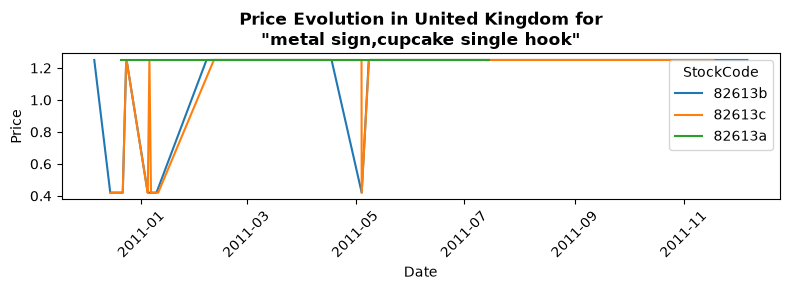

In [20]:
plot_product_price_evolution(df_clean, 'metal sign,cupcake single hook')

The different codes behind one description look like **variants of the same product** rather than separate offers: they show the same price points over time (for example, 1.25 and 0.42 for `metal sign,cupcake single hook`). Besides, only a few descriptions are affected, and a single `StockCode` already takes several prices across the dataset.

Therefore, variants are collapsed into a new column, `ProductCode`, holding the **most frequent** `StockCode` of each description (ties are broken by the smallest code). The original `StockCode` is kept, so no information is lost.

In [21]:
# Assign one representative ProductCode to each description using its most frequent StockCode.
df_clean['ProductCode'] = df_clean['Description'].map(df_description_unique_codes['Mode_Code'])

n_changed = (df_clean['ProductCode'] != df_clean['StockCode']).sum()
print(f'{n_changed} rows have a ProductCode different from their StockCode')
print(f'Number of unique StockCodes:   {df_clean["StockCode"].nunique()}')
print(f'Number of unique ProductCodes: {df_clean["ProductCode"].nunique()}')
print(f'Number of unique Descriptions: {df_clean["Description"].nunique()}')

# ProductCode and Description are now in one-to-one correspondence
assert df_clean.groupby('Description')['ProductCode'].nunique().max() == 1
assert df_clean.groupby('ProductCode')['Description'].nunique().max() == 1

613 rows have a ProductCode different from their StockCode
Number of unique StockCodes:   3674
Number of unique ProductCodes: 3645
Number of unique Descriptions: 3645


### **3.6 Prices**

#### **3.6.1 Zero and Symbolic Prices**

In [22]:
mask_price_zero = df_clean['UnitPrice'] <= 1e-4

df_price_zero = df_clean[mask_price_zero]

print(f'Rows with zero or symbolic UnitPrice (<= 0.0001): {df_price_zero.shape[0]}')
print(f'Unique Product Codes with zero or symbolic UnitPrice: {df_price_zero["ProductCode"].nunique()}')
print("\nSample of rows with zero or symbolic UnitPrice:\n")

df_price_zero.head()

Rows with zero or symbolic UnitPrice (<= 0.0001): 33
Unique Product Codes with zero or symbolic UnitPrice: 33

Sample of rows with zero or symbolic UnitPrice:



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ProductCode
6986,537197,22841,round cake tin vintage green,1,2010-12-05 14:02:00,0.0,12647,germany,22841
22988,539263,22580,advent calendar gingham sack,4,2010-12-16 14:36:00,0.0,16560,united kingdom,22580
25937,539722,22423,regency cakestand 3 tier,10,2010-12-21 13:45:00,0.0,14911,eire,22423
29750,540372,22090,paper bunting retrospot,24,2011-01-06 16:41:00,0.0,13081,united kingdom,22090
29752,540372,22553,plasters in tin skulls,24,2011-01-06 16:41:00,0.0,13081,united kingdom,22553


In [23]:
# The same product usually has a positive price in other invoices
print("Checking pricing history for product '22841' to see if it has valid prices in other transactions:\n")
df_clean[df_clean['ProductCode'] == '22841'].sort_values('UnitPrice').head(10)

Checking pricing history for product '22841' to see if it has valid prices in other transactions:



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ProductCode
6986,537197,22841,round cake tin vintage green,1,2010-12-05 14:02:00,0.00,12647,germany,22841
257552,567860,22841,round cake tin vintage green,4,2011-09-22 13:53:00,5.49,18102,united kingdom,22841
257335,567852,22841,round cake tin vintage green,36,2011-09-22 13:21:00,5.49,18102,united kingdom,22841
40426,541789,22841,round cake tin vintage green,4,2011-01-21 13:07:00,6.95,14088,united kingdom,22841
64131,544690,22841,round cake tin vintage green,12,2011-02-23 08:48:00,6.95,14156,eire,22841
71025,545475,22841,round cake tin vintage green,36,2011-03-03 10:59:00,6.95,12415,australia,22841
41961,541932,22841,round cake tin vintage green,12,2011-01-24 11:39:00,6.95,14439,greece,22841
49996,542933,22841,round cake tin vintage green,12,2011-02-02 10:56:00,6.95,14411,united kingdom,22841
317250,573320,22841,round cake tin vintage green,12,2011-10-30 10:29:00,6.95,15513,united kingdom,22841
208125,562447,22841,round cake tin vintage green,12,2011-08-04 19:20:00,6.95,15251,united kingdom,22841


Based on the finding that these products actually have normal, positive prices in other invoices, we have decided to **delete these zero-price rows instead of imputing them** (for example, with the median price) for two reasons:
- there are very few of them (only 33 rows), so deleting them has a negligible effect on our dataset;
- imputing a price requires looking at the overall price distribution, which is part of the Exploratory Data Analysis (EDA) in the next notebook, and we should not anticipate that step here.

In [24]:
# Remove rows with UnitPrice = 0 (or symbolic)

num_rows_before = df_clean.shape[0]
print(f'Rows before removing zero-price lines: {num_rows_before}')

df_clean = df_clean[~mask_price_zero].reset_index(drop=True)

num_rows_after = df_clean.shape[0]
print(f'Rows after removing zero-price lines: {num_rows_after}')
print(f'Zero-price lines removed: {num_rows_before - num_rows_after}')

Rows before removing zero-price lines: 404826
Rows after removing zero-price lines: 404793
Zero-price lines removed: 33


#### **3.6.2 Volume Discounts**

Let's check if the same product appears with more than one price in the same invoice.

In [25]:
# Detect products recorded at multiple unit prices within the same invoice.
df_unique_price_code = df_clean.groupby(['Country', 'InvoiceNo', 'StockCode'])['UnitPrice'].agg(
    Nunique_Price='nunique'
)
mask_more_than_1_price = df_unique_price_code['Nunique_Price'] > 1

has_multiple_prices = mask_more_than_1_price.any()
print(f"Is there just one unique price per product code in the same invoice? {'No' if has_multiple_prices else 'Yes'}")
if has_multiple_prices:
    df_more_than_1_price = df_unique_price_code[mask_more_than_1_price]
    print(f'Number of Stock Codes with more than one price in the same invoice: {df_more_than_1_price.shape[0]}')
    print(f'Maximum number of different prices mapped to a single invoice and stock code: {df_more_than_1_price['Nunique_Price'].max()}')
    print("\nSample of stock codes with multiple prices in the same invoice:\n")
    display(df_more_than_1_price.head())

Is there just one unique price per product code in the same invoice? No
Number of Stock Codes with more than one price in the same invoice: 69
Maximum number of different prices mapped to a single invoice and stock code: 2

Sample of stock codes with multiple prices in the same invoice:



Nunique_Price
Country InvoiceNo StockCode               
denmark 556127    22383                  2
eire    570700    22423                  2
finland 539318    21213                  2
                  21977                  2
                  22952                  2

In [26]:
# Let's take a look: maybe there is a sort of volume discount

if has_multiple_prices:
    mask = df_clean.set_index(['Country', 'InvoiceNo', 'StockCode']).index.isin(df_more_than_1_price.index)
    print("Detailed transaction rows where different unit prices coexist for the same product in an invoice:\n")
    display(df_clean[mask].sort_values(['InvoiceNo', 'StockCode']).head(10))

Detailed transaction rows where different unit prices coexist for the same product in an invoice:



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ProductCode
7888,537236,22073,red retrospot storage jar,16,2010-12-06 09:52:00,3.39,16858,united kingdom,22073
7894,537236,22073,red retrospot storage jar,8,2010-12-06 09:52:00,3.75,16858,united kingdom,22073
10560,537624,72800e,4 ivory dinner candles silver flock,12,2010-12-07 14:41:00,2.10,12748,united kingdom,72800e
10614,537624,72800e,4 ivory dinner candles silver flock,2,2010-12-07 14:41:00,2.55,12748,united kingdom,72800e
22148,539102,21181,please one person metal sign,144,2010-12-16 10:37:00,1.53,16029,united kingdom,21181
22150,539102,21181,please one person metal sign,144,2010-12-16 10:37:00,1.65,16029,united kingdom,21181
23479,539318,21213,pack of 72 skull cake cases,24,2010-12-16 19:09:00,0.55,12348,finland,21213
23480,539318,21213,pack of 72 skull cake cases,120,2010-12-16 19:09:00,0.42,12348,finland,21213
23489,539318,21977,pack of 60 pink paisley cake cases,24,2010-12-16 19:09:00,0.55,12348,finland,21977
23490,539318,21977,pack of 60 pink paisley cake cases,120,2010-12-16 19:09:00,0.42,12348,finland,21977


Many of these cases look like **volume discounts** (for instance, in invoice 539318 the larger quantity has the lower price), although not all of them (invoice 539102 buys 144 units at both prices). No action is needed: purchases are consolidated by price in section 4.1, so both lines are preserved.

In [27]:
# Verifying that the price inconsistency for 'PLEASE ONE PERSON METAL SIGN' originates from the source data
print("Verifying invoice '539102' in the original raw dataset (df_raw) to confirm that the multiple prices")
print("for 'PLEASE ONE PERSON METAL SIGN' (StockCode 21181) were already present prior to cleaning:\n")
display(df_raw[df_raw.InvoiceNo=='539102'].sort_values('Description'))

Verifying invoice '539102' in the original raw dataset (df_raw) to confirm that the multiple prices
for 'PLEASE ONE PERSON METAL SIGN' (StockCode 21181) were already present prior to cleaning:



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
32675,539102,85152,HAND OVER THE CHOCOLATE SIGN,144,2010-12-16 10:37:00,1.53,16029,United Kingdom
32673,539102,85150,LADIES & GENTLEMEN METAL SIGN,144,2010-12-16 10:37:00,1.69,16029,United Kingdom
32672,539102,22174,PHOTO CUBE,408,2010-12-16 10:37:00,1.25,16029,United Kingdom
32674,539102,21181,PLEASE ONE PERSON METAL SIGN,144,2010-12-16 10:37:00,1.53,16029,United Kingdom
32676,539102,21181,PLEASE ONE PERSON METAL SIGN,144,2010-12-16 10:37:00,1.65,16029,United Kingdom


### **3.7 Zero Quantities**

In [28]:
# Remove rows with Quantity = 0, if any

num_rows_before = df_clean.shape[0]
print(f'Rows before removing zero-quantity lines: {num_rows_before}')

mask_zero_quantity = df_clean['Quantity'] == 0
if mask_zero_quantity.any():
    print(f'Zero-quantity lines identified: {mask_zero_quantity.sum()}')
    df_clean = df_clean[~mask_zero_quantity].reset_index(drop=True)

num_rows_after = df_clean.shape[0]
if num_rows_before != num_rows_after:
    print(f'Rows after removing zero-quantity lines: {num_rows_after}')
    print(f'Zero-quantity lines removed: {num_rows_before - num_rows_after}')
else:
    print('No rows were removed')

Rows before removing zero-quantity lines: 404793
No rows were removed


### **3.8 Unspecified Country**

In [29]:
print(f'Number of unique countries: {df_clean["Country"].nunique(dropna=False)}\n')
print(f'Unique countries:\n{df_clean["Country"].sort_values().unique().tolist()}')

Number of unique countries: 37

Unique countries:
['australia', 'austria', 'bahrain', 'belgium', 'brazil', 'canada', 'channel islands', 'cyprus', 'czech republic', 'denmark', 'eire', 'european community', 'finland', 'france', 'germany', 'greece', 'iceland', 'israel', 'italy', 'japan', 'lebanon', 'lithuania', 'malta', 'netherlands', 'norway', 'poland', 'portugal', 'rsa', 'saudi arabia', 'singapore', 'spain', 'sweden', 'switzerland', 'united arab emirates', 'united kingdom', 'unspecified', 'usa']


In [30]:
mask_unspecified = df_clean['Country'] == 'unspecified'
print(f'Number of rows with "unspecified" country: {mask_unspecified.sum()}')

# Customers associated to the "unspecified" country
unspecified_customers = df_clean.loc[mask_unspecified, 'CustomerID'].unique()
print(f'Number of unique customers with "unspecified" country: {len(unspecified_customers)}')
print(f'Unique customers with "unspecified" country: {unspecified_customers.tolist()}\n')

# Check if those customers have other countries besides "unspecified"
countries_by_customer = (df_clean[df_clean['CustomerID'].isin(unspecified_customers)]
                         .groupby('CustomerID')['Country'].unique())
for customer, countries in countries_by_customer.items():
    print(f'Customer {customer} has associated countries: {countries.tolist()}')

can_impute = (countries_by_customer.apply(len) > 1).any()
if can_impute:
    print('\nNow, proceed with imputation of "unspecified" country')
else:
    print('\nNow, proceed with removing rows with "unspecified" country')

Number of rows with "unspecified" country: 244
Number of unique customers with "unspecified" country: 4
Unique customers with "unspecified" country: ['12363', '16320', '14265', '12743']

Customer 12363 has associated countries: ['unspecified']
Customer 12743 has associated countries: ['unspecified']
Customer 14265 has associated countries: ['unspecified']
Customer 16320 has associated countries: ['unspecified']

Now, proceed with removing rows with "unspecified" country


None of these customers has another country, so the country cannot be imputed and the rows are removed.

In [31]:
num_rows_before = df_clean.shape[0]
print(f'Rows before removing lines with unspecified country: {num_rows_before}')

df_clean = df_clean[df_clean['Country'] != 'unspecified'].reset_index(drop=True)

num_rows_after = df_clean.shape[0]
print(f'Rows after removing lines with unspecified country: {num_rows_after}')
print(f'Rows with unspecified country removed: {num_rows_before - num_rows_after}')

Rows before removing lines with unspecified country: 404793
Rows after removing lines with unspecified country: 404549
Rows with unspecified country removed: 244


### **3.9 Continent Feature**

Customers are grouped by continent to reduce the number of country categories. The mapping is built from the countries present in the cleaned data.

In [32]:
# Map each country label present in this dataset to a continent category.
country_continent_dict = {
    'australia': 'oceania',
    'austria': 'europe',
    'bahrain': 'asia',
    'belgium': 'europe',
    'brazil': 'south america',
    'canada': 'north america',
    'channel islands': 'europe',  # Geographically closer to europe
    'cyprus': 'europe',  # Geographically closer to europe
    'czech republic': 'europe',
    'denmark': 'europe',
    'eire': 'europe',  # Republic of Ireland
    'european community': 'europe',  # Represents a group of european countries
    'finland': 'europe',
    'france': 'europe',
    'germany': 'europe',
    'greece': 'europe',
    'iceland': 'europe',
    'israel': 'asia',
    'italy': 'europe',
    'japan': 'asia',
    'lebanon': 'asia',
    'lithuania': 'europe',
    'malta': 'europe',
    'netherlands': 'europe',
    'norway': 'europe',
    'poland': 'europe',
    'portugal': 'europe',
    'rsa': 'africa',  # Republic of South Africa
    'saudi arabia': 'asia',
    'singapore': 'asia',
    'spain': 'europe',
    'sweden': 'europe',
    'switzerland': 'europe',
    'united arab emirates': 'asia',
    'united kingdom': 'europe',
    'usa': 'north america'
}

print(f'Number of countries in the dictionary: {len(country_continent_dict)}')

Number of countries in the dictionary: 36


In [33]:
# assign Country to a Continent

df_clean['Continent'] = df_clean['Country'].map(country_continent_dict)

# Fail if any country is missing from the dictionary
assert df_clean['Continent'].notna().all(), \
    f"Unmapped countries: {df_clean.loc[df_clean['Continent'].isna(), 'Country'].unique().tolist()}"

print('Sample of rows with new "Continent" column:\n')
display(df_clean.head())

Sample of rows with new "Continent" column:



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ProductCode,Continent
0,536365,85123a,cream hanging heart t-light holder,6,2010-12-01 08:26:00,2.55,17850,united kingdom,85123a,europe
1,536365,71053,white moroccan metal lantern,6,2010-12-01 08:26:00,3.39,17850,united kingdom,71053,europe
2,536365,84406b,cream cupid hearts coat hanger,8,2010-12-01 08:26:00,2.75,17850,united kingdom,84406b,europe
3,536365,84029g,knitted union flag hot water bottle,6,2010-12-01 08:26:00,3.39,17850,united kingdom,84029g,europe
4,536365,84029e,red woolly hottie white heart.,6,2010-12-01 08:26:00,3.39,17850,united kingdom,84029e,europe


### **3.10 One Timestamp per Invoice**

Lines of the same invoice should share the same date and time. Let's check it.

In [34]:
# Compare the earliest and latest timestamps recorded for each invoice.
df_diff_dates = df_clean.groupby(['Country', 'InvoiceNo'])['InvoiceDate'].agg(
    date_min='min',
    date_max='max'
)
df_diff_dates['diff'] = df_diff_dates['date_max'] - df_diff_dates['date_min']
df_diff_dates['diff_seconds'] = df_diff_dates['diff'].dt.total_seconds()

print(f'Number of invoices with different dates: {len(df_diff_dates[df_diff_dates["diff_seconds"] > 0])}')
print(f'Minimum / Maximum difference in seconds: {df_diff_dates["diff_seconds"].min()} / {df_diff_dates["diff_seconds"].max()}')
print("\nSample of invoices with different timestamps across their lines (non-zero difference in seconds):\n")
display(df_diff_dates[df_diff_dates['diff_seconds'] > 0].head())

Number of invoices with different dates: 31
Minimum / Maximum difference in seconds: 0.0 / 60.0

Sample of invoices with different timestamps across their lines (non-zero difference in seconds):



date_min            date_max  \
Country        InvoiceNo                                           
eire           553375    2011-05-16 14:52:00 2011-05-16 14:53:00   
france         541631    2011-01-20 10:47:00 2011-01-20 10:48:00   
japan          543179    2011-02-04 10:31:00 2011-02-04 10:32:00   
united kingdom 536591    2010-12-01 16:57:00 2010-12-01 16:58:00   
               540185    2011-01-05 13:40:00 2011-01-05 13:41:00   

                                    diff  diff_seconds  
Country        InvoiceNo                                
eire           553375    0 days 00:01:00          60.0  
france         541631    0 days 00:01:00          60.0  
japan          543179    0 days 00:01:00          60.0  
united kingdom 536591    0 days 00:01:00          60.0  
               540185    0 days 00:01:00          60.0

A few invoices have lines registered with different timestamps (at most one minute apart). The latest timestamp is assigned to the whole invoice.

In [35]:
# Use the latest timestamp so every line belonging to an invoice shares one timestamp.

df_clean['InvoiceDate'] = df_clean.groupby(['Country', 'InvoiceNo'])['InvoiceDate'].transform('max')

## **4. Consolidate Purchases and Returns**

Returns are lines with a negative `Quantity` (invoices starting with "c"). This section groups the invoice lines and makes the returns consistent with the purchases.

A return is matched to purchases of the **same customer, product (`StockCode`) and unit price**.

Returns are kept as separate lines (negative `Quantity`). How to use them later (for example, netting them in the monetary value of the RFM, or attaching them to the purchases they refer to) is left for the next notebook.

### **4.1 Aggregate Invoice Lines**

Lines with the same customer, product, price, invoice and date are summed into a single line.

In [36]:
# These columns define the customer-product-price balance used to match returns with purchases.
GROUP_KEY = ['Continent', 'Country', 'CustomerID', 'StockCode', 'UnitPrice']
# Columns identifying one invoice row
ROW_KEY = GROUP_KEY + ['ProductCode', 'Description', 'InvoiceDate', 'InvoiceNo']

num_rows_before = df_clean.shape[0]
print(f'Rows before consolidating invoice lines: {num_rows_before}')

dfc = df_clean.groupby(ROW_KEY, as_index=False)['Quantity'].sum()

# Chronological order within each customer-product-price group (required by the next steps)
dfc = dfc.sort_values(GROUP_KEY + ['InvoiceDate', 'InvoiceNo']).reset_index(drop=True)

num_rows_after = dfc.shape[0]
print(f'Rows after consolidating invoice lines: {num_rows_after}')

if num_rows_before != num_rows_after:
    print(f'Rows consolidated (net reduction): {num_rows_before - num_rows_after}')
else:
    print('No rows were removed')

# The total value must not change
assert np.isclose((dfc['UnitPrice'] * dfc['Quantity']).sum(), (df_clean['UnitPrice'] * df_clean['Quantity']).sum())

Rows before consolidating invoice lines: 404549
Rows after consolidating invoice lines: 394548
Rows consolidated (net reduction): 10001


In [37]:
def show_customer_product(df, customer_id, product_code):
    """Display the lines of a customer for a product (matching either StockCode or ProductCode)."""
    mask = (df['CustomerID'] == customer_id) & ((df['StockCode'] == product_code) | (df['ProductCode'] == product_code))
    display(df[mask])

print("Consolidated transactions for Customer '12472' and Product '22467' (identical lines merged):\n")
show_customer_product(dfc, customer_id='12472', product_code='22467')

Consolidated transactions for Customer '12472' and Product '22467' (identical lines merged):



,Continent,Country,CustomerID,StockCode,UnitPrice,ProductCode,Description,InvoiceDate,InvoiceNo,Quantity
22125,europe,germany,12472,22467,2.10,22467,gumball coat rack,2011-03-17 12:40:00,546843,36
22126,europe,germany,12472,22467,2.10,22467,gumball coat rack,2011-10-19 11:49:00,571824,36
22127,europe,germany,12472,22467,2.55,22467,gumball coat rack,2010-12-05 14:19:00,537201,12
22128,europe,germany,12472,22467,2.55,22467,gumball coat rack,2011-01-26 12:27:00,542215,18
22129,europe,germany,12472,22467,2.55,22467,gumball coat rack,2011-02-07 12:44:00,c543347,-6
22130,europe,germany,12472,22467,2.55,22467,gumball coat rack,2011-03-30 15:12:00,c548356,-9
22131,europe,germany,12472,22467,2.55,22467,gumball coat rack,2011-06-13 14:13:00,556578,6
22132,europe,germany,12472,22467,2.55,22467,gumball coat rack,2011-07-07 11:44:00,c559253,-2
22133,europe,germany,12472,22467,2.55,22467,gumball coat rack,2011-07-24 11:55:00,561037,6
22134,europe,germany,12472,22467,2.55,22467,gumball coat rack,2011-11-08 12:39:00,c575064,-8


### **4.2 Match Returns to Purchases**

A return cannot give back more than what the customer holds. Two situations need to be fixed:
- **Returns without a previous purchase** of the same product and price (the purchase happened before the dataset starts, or at another price): they are deleted.
- **Returns larger than the accumulated purchases**: they are reduced to the accumulated quantity.

In [38]:
print("Example of Returns without previous purchase:\n")
customerId = '17204'
productId  = '22796'
show_customer_product(dfc, customer_id=customerId, product_code=productId)

print()

print("Example of Returns larger than the accumulated purchases:\n")
customerId = '13694'
productId  = '51014c'
show_customer_product(dfc, customer_id=customerId, product_code=productId)

Example of Returns without previous purchase:



,Continent,Country,CustomerID,StockCode,UnitPrice,ProductCode,Description,InvoiceDate,InvoiceNo,Quantity
319491,europe,united kingdom,17204,22796,8.50,22796,photo frame 3 classic hanging,2011-04-18 12:55:00,c550451,-4
319492,europe,united kingdom,17204,22796,9.95,22796,photo frame 3 classic hanging,2011-04-12 15:32:00,549885,6



Example of Returns larger than the accumulated purchases:



,Continent,Country,CustomerID,StockCode,UnitPrice,ProductCode,Description,InvoiceDate,InvoiceNo,Quantity
96641,europe,united kingdom,13694,51014c,0.39,51014c,"feather pen,coal black",2011-09-15 12:56:00,566867,120
96642,europe,united kingdom,13694,51014c,0.39,51014c,"feather pen,coal black",2011-09-27 11:16:00,c568419,-192


**How the return adjustment works:** rows are processed chronologically within each customer–product–price group. A cumulative quantity tracks units available after purchases and returns. The function keeps purchases unchanged, limits each return to the units still available, and turns unsupported excess returns into zero; those zero-quantity lines are removed in the next cell.


In [39]:
def cap_returns(df, key=GROUP_KEY):
    """
    Cap each return (negative Quantity) at the units the customer still holds.

    Rows must be sorted chronologically within each `key` group. Purchases are
    kept as they are; a return with nothing left to give back becomes 0.
    Returns a Series aligned with `df`.
    """
    group = df.groupby(key, sort=False).ngroup()
    running = df['Quantity'].groupby(group).cumsum()
    # Reflect the cumulative balance at zero so returns cannot create a negative stock balance.
    balance = running - running.groupby(group).cummin().clip(upper=0)
    # Units actually moved at each step = change in the reflected balance
    return balance.groupby(group).diff().fillna(balance).astype('int64')

In [40]:
num_rows_before = dfc.shape[0]
print(f'Rows before adjusting returns: {num_rows_before}')

# GROUP_KEY = ['Continent', 'Country', 'CustomerID', 'StockCode', 'UnitPrice']
fitted_quantity = cap_returns(dfc)

# Count returns that were reduced but still have a non-zero quantity.
n_adjusted = ((fitted_quantity != dfc['Quantity']) & (fitted_quantity != 0)).sum()

dfc['Quantity'] = fitted_quantity
dfc = dfc[dfc['Quantity'] != 0].reset_index(drop=True)

num_rows_after = dfc.shape[0]
print(f'Rows after adjusting returns: {num_rows_after}')
print(f'Rows removed (returns with no available prior purchase): {num_rows_before - num_rows_after}')
print(f'Returns reduced to the available accumulated quantity: {n_adjusted}')

Rows before adjusting returns: 394548
Rows after adjusting returns: 393189
Rows removed (returns with no available prior purchase): 1359
Returns reduced to the available accumulated quantity: 54


In [41]:
# Check results

customerId = '17204'
productId  = '22796'
print(f"Verifying Customer {customerId} for Product {productId} after adjusting returns (returns with no prior purchases are removed):\n")
show_customer_product(dfc, customer_id=customerId, product_code=productId)

print()

customerId = '13694'
productId  = '51014c'
print(f"Verifying Customer {customerId} for Product {productId} after adjusting returns (returns capped at available accumulated quantity):\n")
show_customer_product(dfc, customer_id=customerId, product_code=productId)

Verifying Customer 17204 for Product 22796 after adjusting returns (returns with no prior purchases are removed):



,Continent,Country,CustomerID,StockCode,UnitPrice,ProductCode,Description,InvoiceDate,InvoiceNo,Quantity
318353,europe,united kingdom,17204,22796,9.95,22796,photo frame 3 classic hanging,2011-04-12 15:32:00,549885,6



Verifying Customer 13694 for Product 51014c after adjusting returns (returns capped at available accumulated quantity):



,Continent,Country,CustomerID,StockCode,UnitPrice,ProductCode,Description,InvoiceDate,InvoiceNo,Quantity
96306,europe,united kingdom,13694,51014c,0.39,51014c,"feather pen,coal black",2011-09-15 12:56:00,566867,120
96307,europe,united kingdom,13694,51014c,0.39,51014c,"feather pen,coal black",2011-09-27 11:16:00,c568419,-120


In [42]:
# Validate that the running quantity never becomes negative within a customer-product-price group.
running_balance = dfc.groupby(GROUP_KEY)['Quantity'].cumsum()
assert (running_balance >= 0).all()

print(f'Purchase lines: {(dfc["Quantity"] > 0).sum()} | Return lines: {(dfc["Quantity"] < 0).sum()}')

Purchase lines: 386072 | Return lines: 7117


## **5. Export Cleaned Dataset**

The cleaned dataset (`data/cleaned_data.csv`) is the input of the next notebooks. One row per invoice line, with these columns:

| Column | Description |
|---|---|
| `InvoiceNo` | Invoice number (string). Returns have an invoice starting with "c" |
| `InvoiceDate` | Date and time of the invoice (one value per invoice) |
| `CustomerID` | Customer identifier (string) |
| `Country`, `Continent` | Customer's country and continent (lowercase) |
| `StockCode` | Original product code (variants are kept) |
| `ProductCode` | Product key: most frequent `StockCode` of the description. **Use it to identify products** |
| `Description` | Product description (lowercase) |
| `UnitPrice` | Price per unit |
| `Quantity` | Units in the line: positive for purchases, negative for returns. Returns are already adjusted (see 4.2): none exceeds the units previously purchased |

When reading the file, `InvoiceNo`, `StockCode`, `ProductCode` and `CustomerID` should be loaded as strings and `InvoiceDate` parsed as a date.

In [43]:
# Keep only the fields needed by the next analysis notebooks.
final_columns = ['InvoiceNo', 'InvoiceDate', 'CustomerID', 'Country', 'Continent',
                 'StockCode', 'ProductCode', 'Description', 'UnitPrice', 'Quantity']

dfc_final = dfc[final_columns].sort_values(['InvoiceNo', 'StockCode']).reset_index(drop=True)

print(f'Final cleaned dataset shape (rows, columns): {dfc_final.shape}\n')
print("Cleaned dataset overview:\n")
display(dfc_final.head(10))

# Sanity check: each invoice has one customer
assert dfc_final.InvoiceNo.nunique() == len(set(zip(dfc_final.InvoiceNo, dfc_final.CustomerID)))

Final cleaned dataset shape (rows, columns): (393189, 10)

Cleaned dataset overview:



,InvoiceNo,InvoiceDate,CustomerID,Country,Continent,StockCode,ProductCode,Description,UnitPrice,Quantity
0,536365,2010-12-01 08:26:00,17850,united kingdom,europe,21730,21730,glass star frosted t-light holder,4.25,6
1,536365,2010-12-01 08:26:00,17850,united kingdom,europe,22752,22752,set 7 babushka nesting boxes,7.65,2
2,536365,2010-12-01 08:26:00,17850,united kingdom,europe,71053,71053,white moroccan metal lantern,3.39,6
3,536365,2010-12-01 08:26:00,17850,united kingdom,europe,84029e,84029e,red woolly hottie white heart.,3.39,6
4,536365,2010-12-01 08:26:00,17850,united kingdom,europe,84029g,84029g,knitted union flag hot water bottle,3.39,6
5,536365,2010-12-01 08:26:00,17850,united kingdom,europe,84406b,84406b,cream cupid hearts coat hanger,2.75,8
6,536365,2010-12-01 08:26:00,17850,united kingdom,europe,85123a,85123a,cream hanging heart t-light holder,2.55,6
7,536366,2010-12-01 08:28:00,17850,united kingdom,europe,22632,22632,hand warmer red retrospot,1.85,6
8,536366,2010-12-01 08:28:00,17850,united kingdom,europe,22633,22633,hand warmer union jack,1.85,6
9,536367,2010-12-01 08:34:00,13047,united kingdom,europe,21754,21754,home building block word,5.95,3


In [44]:
# Save csv
dfc_final.to_csv(os.path.join(extract_folder, 'cleaned_data.csv'), index=False)

print(f'Exported {dfc_final.shape[0]} rows and {dfc_final.shape[1]} columns to "{os.path.join(extract_folder, "cleaned_data.csv")}"')

Exported 393189 rows and 10 columns to "data\cleaned_data.csv"


**Next notebook:** EDA and simple RFM analysis, where the treatment of return lines will be decided.